# TR / Repetition Time — Few-shot 2

Read and validate BIDS RepetitionTime metadata.

This notebook uses a real BIDS file from OpenNeuro ds000114. It stops with a clear error when the dataset is not downloaded.

In [1]:
from pathlib import Path
import os, glob, json
import numpy as np

# Set FMRI_BIDS_ROOT to a downloaded OpenNeuro ds000114 directory.
BIDS_ROOT = Path(os.environ.get("FMRI_BIDS_ROOT", "data/ds000114"))
files = sorted(BIDS_ROOT.rglob("*_bold.nii.gz"))
if not files:
    raise FileNotFoundError("No BOLD NIfTI found. Download ds000114 and set FMRI_BIDS_ROOT.")
print("Using real BIDS input:", files[0])
import nibabel as nib
img = nib.load(files[0])
arr = np.asarray(img.get_fdata(), dtype=float)
print("shape", arr.shape, "zooms", img.header.get_zooms())
import sys
HERE = Path.cwd()
for parent in [HERE, *HERE.parents]:
    candidate = parent / "src" / "validate_tr.py"
    if candidate.exists():
        sys.path.insert(0, str(candidate.parent))
        break
from validate_tr import validate_tr


Using real BIDS input: /Users/liuxiang/fMRI-preprocess/data/ds000114/sub-01/ses-test/func/sub-01_ses-test_task-fingerfootlips_bold.nii.gz


shape (64, 64, 30, 184) zooms (4.0, 4.0, 3.999975, 2.5)


In [2]:
meta_path=Path(str(files[0]).replace('_bold.nii.gz','.json'))
if not meta_path.exists(): meta_path=BIDS_ROOT / 'task-fingerfootlips_bold.json'
meta=json.loads(meta_path.read_text())
print(validate_tr(meta))


{'tr_seconds': 2.5, 'matches': True}


## Quantitative checks and common errors

Inspect shape, affine, NaNs, and the metric above before writing derivatives. Do not silently resample, trim, or regress without recording parameters in BIDS `desc-` metadata.

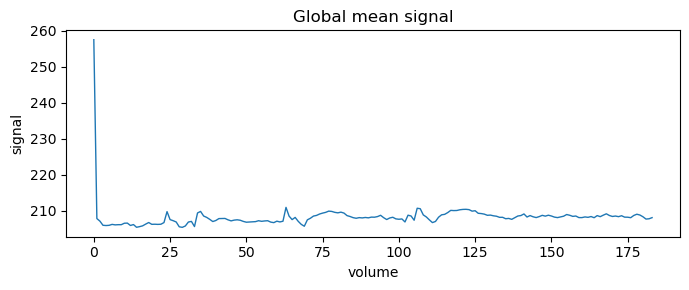

In [3]:
import matplotlib.pyplot as plt
mean_ts = np.nanmean(arr.reshape(-1, arr.shape[-1]), axis=0)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(mean_ts, linewidth=1)
ax.set(title="Global mean signal", xlabel="volume", ylabel="signal")
fig.tight_layout()
plt.show()
